# TPC_Calibration: アノード × カソードの同時計数 → 反跳電子のエネルギー

`CalcFADC` の電荷は FADC の ch(32 ストリップの和)ごとなので、そのままではアノードの ch とカソードの ch のどの組の信号か分かりません。
`TPC_Calibration` は、**同じクロック・同じパネルで鳴ったアノードとカソードのストリップの組(同時計数)**を数え、その数で重みを付けて、
ch の組ごとのゲイン(ゲインマップ)で電荷をエネルギーにします。

| 手順 | 中身 |
|---|---|
| 1. 同時計数 | 同じクロックで、アノードのストリップ a とカソードのストリップ c が両方鳴り、`a / 384 == c / 384`(同じパネル)なら 1 つ数える。a, c の FADC の ch の組 (i, j) ごとに `HitPanel[i][j]` に足す |
| 2. エネルギー | アノードの ch i ごとに、$E \mathrel{+}= \sum_j (K_{a,ij}\,Q_i + K_{b,ij}) \times \mathrm{HitPanel}_{ij} / \sum_j \mathrm{HitPanel}_{ij}$ |
| 3. ゲインマップ無し | `NoCalData: true` なら $E = \sum_i Q_i$(同時計数のあるアノードの ch の電荷の和)[ADU × サンプル] |
| 4. 印 | $E \ne 0$ なら `TPC_Ee_Valid`(SMILE_tool_box の evs "Ee")。イベントは飛ばさない。`Reconstruct` はこの印を見る |

ゲインマップ `ParameterFile` は 1 行に `i j Ka Kb`(アノードの ch、カソードの ch、傾き、切片)です。SMILE-3 のゲインマップはまだ無いので、
設定ファイルでは `NoCalData: true` で、エネルギーの単位は ADU × サンプルです。

SMILE_tool_box(と EricaNext_try)の TPC_Calibration は、同時計数が 100 を超えるパネルだけを足しますが、SMILE-3 版にはまだその条件がありません。
また 2026-11-06 に、`NoCalData` のときに最後の ch の電荷しか残らなかった(`=` だった)のを、和(`+=`)に直しました。

In [1]:
import os, sys, json, subprocess
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import ROOT
ROOT.gROOT.SetBatch(True)

# リポジトリの場所、チェーンの実行スクリプト、設定ファイル(config/*.json)の読み込み
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "run_script" / "run_chain.py").exists())
RUN_CHAIN = REPO / "run_script" / "run_chain.py"
sys.path.insert(0, str(REPO / "config"))
import ericanext_config as ec
CACHE = REPO / "tutorials" / "cache"   # チェーンの出力の置き場(チュートリアル間で共有、git には入れない)
CACHE.mkdir(exist_ok=True)

def th2(h):
    """ROOT の TH2 -> (中身 [x のビン, y のビン], x のビンの端, y のビンの端)"""
    nx, ny = h.GetNbinsX(), h.GetNbinsY()
    dt = np.float32 if h.InheritsFrom("TArrayF") else np.float64   # TH2F / TH2D
    a = np.frombuffer(h.GetArray(), dtype=dt, count=(nx + 2) * (ny + 2)).reshape(ny + 2, nx + 2).astype(float)
    ex = np.array([h.GetXaxis().GetBinLowEdge(i) for i in range(1, nx + 2)])
    ey = np.array([h.GetYaxis().GetBinLowEdge(i) for i in range(1, ny + 2)])
    return a[1:-1, 1:-1].T.copy(), ex, ey

def th1(h):
    """ROOT の TH1 -> (中身, ビンの中心)"""
    n = h.GetNbinsX()
    return np.array([h.GetBinContent(i) for i in range(1, n + 1)]), np.array([h.GetBinCenter(i) for i in range(1, n + 1)])

def vec(column):
    """RDataFrame.AsNumpy() の配列型の列 -> numpy の配列のリスト"""
    return [np.asarray(v) for v in column]

def show_params(config, module):
    """設定ファイルの、あるモジュールのパラメータを、説明(_doc)と単位(_units)つきで表示する"""
    p = json.load(open(REPO / "config" / f"{config}.json"))["parameters"][module]
    doc, units = p.get("_doc", {}), p.get("_units", {})
    for k, v in p.items():
        if k.startswith("_"):
            continue
        u = f" [{units[k]}]" if k in units else ""
        print(f"{k} = {json.dumps(v, ensure_ascii=False)}{u}\n    {doc.get(k, '')}")

## 1. データの準備

2026-06-23 の TPC の較正データ **`run_20260623T072649Z`**(TPC_cal、アノード 12 枚・カソード 11 枚、約 4 GB、約 228 秒、約 10 万イベント)を使います。
解析用の計算機ではリポジトリの `test.data/` にあります(git には入れていない)。ほかの場所にあるときは、環境変数 `SMILE3_TPC_DATA` にランのディレクトリを設定してください。
1 つのディレクトリにアノードとカソードの全ボードが入っているので、`ReadData` がそのまま読めます
(FM のランのように 2 つの storage に分かれているときは、片方を `--data-dir`、もう片方を `--extra-data-dir` で渡す)。

このランは uPIC0〜2 のレートが安定していて、uPIC3 は電荷がほとんど出ていません。最後の約 10 秒は全 uPIC のレートが跳ね上がる(原因は不明。Notion の「TPC 確認図と QL」)ので、
ここでは先頭の 50000 イベント(約 110 秒)を使います。

In [2]:
RUN_DIR = Path(os.environ.get("SMILE3_TPC_DATA", REPO / "test.data" / "run_20260623T072649Z"))
print("OK     " if RUN_DIR.is_dir() else "MISSING", RUN_DIR)
meta = json.load(open(RUN_DIR / "run_meta.json"))
print("mode:", meta["mode"], " boards:", len(meta["active_detectors"]))

OK      /home/onoda/ANLNext/Erica_git_dev/EricaNext/test.data/run_20260623T072649Z
mode: TPC_cal  boards: 23


## 2. チェーンを流す

設定ファイル `smile3_tpc_only`(`ReadData → CalcFADC → TPC_Calibration → TOT_Skewness`)に、図を作るパラメータを足して先頭 50000 イベントを流します(1 分ほど)。
ターミナルでは、リポジトリの `run_script` で次を実行するのと同じです。

```bash
python3 run_chain.py smile3_tpc_only -o tpc_20260623.root -n 50000 --data-dir ../test.data/run_20260623T072649Z \
    --set ReadData.Image_A_C=true \
    --set TPC_Calibration.Image_XY_TH=true --set TPC_Calibration.Spectrum_TH=true
```

生の波形とヒットは、`smile3_raw`(`ReadData → RawTreeWriter_sm3`)で先頭 5000 イベントをツリーに書いたものから読みます。
出力は `tutorials/cache/` に置き、既にあれば流し直しません(TPC のチュートリアルで共有)。

In [3]:
def run_chain(config, out, *args):
    """run_chain.py を実行する(出力が既にあれば何もしない)。ログを返す"""
    cmd = [sys.executable, str(RUN_CHAIN), config, "-o", str(out), "--data-dir", str(RUN_DIR), *args]
    print(" ".join(cmd))
    if out.exists():
        return ""
    r = subprocess.run(cmd, capture_output=True, text=True)
    if r.returncode != 0:
        print(r.stdout[-3000:], r.stderr[-3000:])
    r.check_returncode()
    (out.parent / (out.name + ".log")).write_text(r.stdout)
    return r.stdout

OUT = CACHE / "tpc_20260623.root"
run_chain("smile3_tpc_only", OUT, "-n", "50000",
          "--set", "ReadData.Image_A_C=true",
          "--set", "TPC_Calibration.Image_XY_TH=true", "--set", "TPC_Calibration.Spectrum_TH=true")
OUT_RAW = CACHE / "tpc_20260623_raw.root"
run_chain("smile3_raw", OUT_RAW, "-n", "5000")
F = ROOT.TFile(str(OUT))

def evs_table(log_path):
    """チェーンのログから、イベント選択(evs)の数の表を取り出す"""
    lines = open(log_path).read().split("Result of Event Selections")[1].splitlines()
    rows = [l.split() for l in lines if len(l.split()) == 3 and l.split()[1].isdigit()]
    return {r[0]: int(r[1]) for r in rows}

/usr/bin/python3 /home/onoda/ANLNext/Erica_git_dev/EricaNext/run_script/run_chain.py smile3_tpc_only -o /home/onoda/ANLNext/Erica_git_dev/EricaNext/tutorials/cache/tpc_20260623.root --data-dir /home/onoda/ANLNext/Erica_git_dev/EricaNext/test.data/run_20260623T072649Z -n 50000 --set ReadData.Image_A_C=true --set TPC_Calibration.Image_XY_TH=true --set TPC_Calibration.Spectrum_TH=true
/usr/bin/python3 /home/onoda/ANLNext/Erica_git_dev/EricaNext/run_script/run_chain.py smile3_raw -o /home/onoda/ANLNext/Erica_git_dev/EricaNext/tutorials/cache/tpc_20260623_raw.root --data-dir /home/onoda/ANLNext/Erica_git_dev/EricaNext/test.data/run_20260623T072649Z -n 5000


## 3. 同時計数の位置

`TPC_Calibration/Image_XY` は、同時計数のアノードのストリップ × カソードのストリップです(`Image_XY_TH: true`)。同じパネルの組だけなので、対角の 4 つの四角になります。

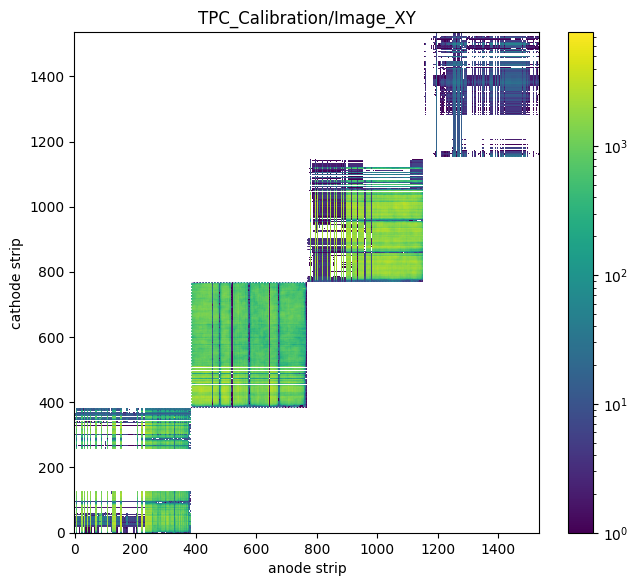

In [4]:
a, ex, ey = th2(F.Get("TPC_Calibration/Image_XY"))
fig, ax = plt.subplots(figsize=(7.5, 6.5))
m = ax.pcolormesh(ex, ey, a.T, norm=LogNorm(vmin=1), shading="flat")
for p in range(1, 4):
    ax.axvline(384 * p, color="w", ls=":", lw=0.8); ax.axhline(384 * p, color="w", ls=":", lw=0.8)
ax.set_xlabel("anode strip"); ax.set_ylabel("cathode strip"); ax.set_title("TPC_Calibration/Image_XY"); fig.colorbar(m)
plt.show()

パネルの中の (a, c) を、0_Introduction の座標(原点は μ-PIC の中央)の (x, y) [mm] に直して並べます。
この変換は `TOT_Skewness` の `Get_TPC_XYZ` と同じです(パネルごとに 90° ずつ回る)。

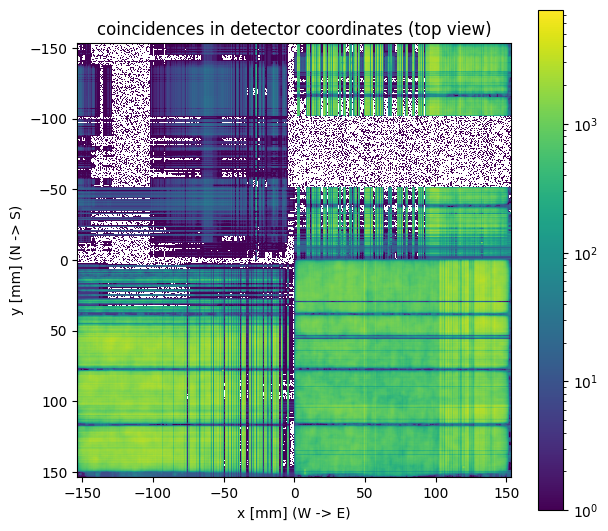

In [5]:
def to_xy(panel, a, c):
    """パネルの中の番号 (a, c) -> (x, y) [mm](0_Introduction、TOT_Skewness と同じ)"""
    tx, ty = {0: (384 + a, c), 1: (767 - c, 384 + a), 2: (383 - a, 767 - c), 3: (c, 383 - a)}[panel]
    return 0.4 * (tx - 383.5), 0.4 * (ty - 383.5)

img = np.zeros((768, 768))
for p in range(4):
    blk = a[384 * p:384 * (p + 1), 384 * p:384 * (p + 1)]
    aa, cc = np.nonzero(blk)
    x, y = to_xy(p, aa, cc)
    np.add.at(img, (np.round(x / 0.4 + 383.5).astype(int), np.round(y / 0.4 + 383.5).astype(int)), blk[aa, cc])
fig, ax = plt.subplots(figsize=(7, 6.5))
m = ax.imshow(img.T, origin="upper", extent=[-153.6, 153.6, 153.6, -153.6], norm=LogNorm(vmin=1))
ax.set_xlabel("x [mm] (W -> E)"); ax.set_ylabel("y [mm] (N -> S)"); ax.set_title("coincidences in detector coordinates (top view)")
fig.colorbar(m); plt.show()

## 4. エネルギー

`TPC_Calibration/Spectrum` は `TPC_Ee_Valid` のイベントのエネルギーです(`Spectrum_TH: true`)。範囲は 0〜400 で、ゲインマップの無い今は ADU × サンプルなので、ほとんどが上にはみ出します。
ここでは `CalcFADC` と同じ電荷の計算と、同時計数のある ch の選び方を、生データのツリーから numpy で書き直して、広い範囲で描きます。

Spectrum: entries 34899, in 0-400: 12484, overflow: 22415
{'TPC_Ee_Valid': 34899} of 50000 events


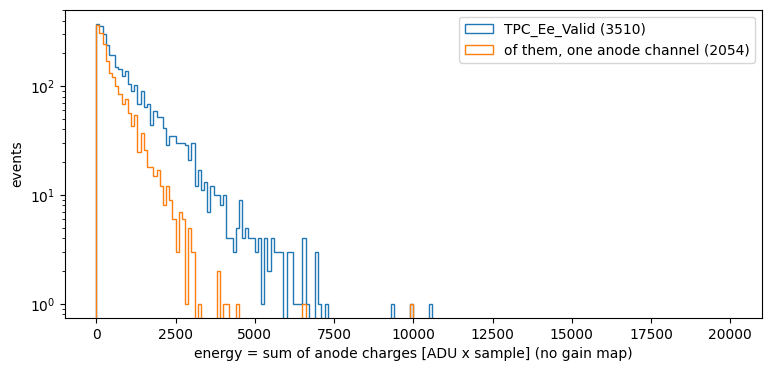

In [6]:
y, x = th1(F.Get("TPC_Calibration/Spectrum"))
h = F.Get("TPC_Calibration/Spectrum")
print(f"Spectrum: entries {int(h.GetEntries())}, in 0-400: {int(y.sum())}, overflow: {int(h.GetBinContent(h.GetNbinsX() + 1))}")
ev = evs_table(str(OUT) + ".log")
print({k: ev[k] for k in ("TPC_Ee_Valid",)}, "of", ev["Anode_Data"], "events")

r = ROOT.RDataFrame("RawTreeWriter_sm3/raw", str(OUT_RAW)).AsNumpy(["fadc_ch", "fadc_wave", "hit_a_strip", "hit_a_clock", "hit_c_strip", "hit_c_clock"])
E, E1 = [], []
for chs, wave, sa, ca, sc, cc in zip(*(r[k] for k in ("fadc_ch", "fadc_wave", "hit_a_strip", "hit_a_clock", "hit_c_strip", "hit_c_clock"))):
    chs = np.asarray(chs); w = np.asarray(wave, dtype=float).reshape(-1, 512)
    x = w[:, 30:] - w[:, :30].mean(axis=1)[:, None]
    q = dict(zip(chs, np.where(x > 20, x, 0).sum(axis=1)))
    A = set(zip(np.asarray(sa), np.asarray(ca))); C = set(zip(np.asarray(sc), np.asarray(cc)))
    by_clk = {}
    for s, k in C:
        by_clk.setdefault(k, []).append(s)
    coin = {s // 32 for s, k in A if any(c // 384 == s // 384 for c in by_clk.get(k, []))}   # アノードの FADC ch(= strip / 32)
    e = sum(q.get(i, 0) for i in coin)
    if e > 0:
        E.append(e)
        if len([i for i in q if i < 48 and q[i] > 0]) == 1:
            E1.append(e)
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(E, bins=200, range=(0, 2e4), histtype="step", label=f"TPC_Ee_Valid ({len(E)})")
ax.hist(E1, bins=200, range=(0, 2e4), histtype="step", label=f"of them, one anode channel ({len(E1)})")
ax.set_yscale("log"); ax.set_xlabel("energy = sum of anode charges [ADU x sample] (no gain map)"); ax.set_ylabel("events")
ax.legend(); plt.show()

アノード 1 ch のイベント(橙)は低い方に寄っていて、高い方は 2 ch 以上にまたがるイベントです。2026-11-06 より前は、橙のイベントだけが `TPC_Calibration` 以降に来ていました。

## 5. パラメータ

In [7]:
show_params("smile3_tpc_only", "TPC_Calibration")

NoCalData = true
    true: ゲインマップを使わず、エネルギー = 電荷 [ADU] とする(ParameterFile は読まない)。false のときは ParameterFile にゲインマップ(E = Ka Q + Kb)を指定する
Coinci_TH = false
    true: アノードとカソードが同じクロック・同じパネル(384 ストリップごと)で鳴ったヒット(ストリップ × クロック)の図 Coinci_A / Coinci_C を作る(イベントごとに作り直す)
Image_XY_TH = false
    true: 同時ヒットのアノード × カソードの位置の図 Image_XY を作る
Spectrum_TH = false
    true: エネルギーのスペクトル Spectrum(0–400 keV、2000 ビン)を作る。NoCalData: true のときは中身が電荷 [ADU] なので、範囲に入らないことが多い
